# Tugas Praktikum 5: Sequential Pattern Analysis

Dataset: Online Retail (UCI Machine Learning Repository)

## 0. Import Library

In [18]:
import time
import matplotlib.pyplot as plt
import pandas as pd
from prefixspan import PrefixSpan

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 200)

## 1. Import Dataset

In [19]:
DATA_PATH = 'Online_Retail.xlsx'
df = pd.read_excel(DATA_PATH)

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [20]:
df.shape

(541909, 8)

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## 2. Eksplorasi dan Pembersihan Data

Kolom yang relevan: **CustomerID** (identitas sequence), **InvoiceDate** (urutan waktu), **InvoiceNo** (pengelompokan itemset), **Description** (item), dan **Quantity** (untuk filter).

In [22]:
def ringkas(d):
    return {'Baris': len(d), 'Invoice': d['InvoiceNo'].nunique(), 'Pelanggan': d['CustomerID'].nunique()}

log = [('Sebelum pembersihan', ringkas(df))]

# 1) Hapus Description kosong
df_clean = df.dropna(subset=['Description'])
log.append(('Hapus Description kosong', ringkas(df_clean)))

# 2) Hapus transaksi dibatalkan (InvoiceNo diawali "C")
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]
log.append(('Hapus transaksi dibatalkan', ringkas(df_clean)))

# 3) Hapus Quantity <= 0
df_clean = df_clean[df_clean['Quantity'] > 0]
log.append(('Hapus Quantity <= 0', ringkas(df_clean)))

# 4) Hapus CustomerID kosong
df_clean = df_clean.dropna(subset=['CustomerID']).copy()
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)
df_clean['Description'] = df_clean['Description'].str.strip()
log.append(('Hapus CustomerID kosong', ringkas(df_clean)))

log.append(('Sesudah pembersihan', ringkas(df_clean)))

pd.DataFrame([{'Tahap': t, **v} for t, v in log]).set_index('Tahap')

,Baris,Invoice,Pelanggan
Tahap,,,
Sebelum pembersihan,541909,25900,4372
Hapus Description kosong,540455,24446,4372
Hapus transaksi dibatalkan,531167,20610,4339
Hapus Quantity <= 0,530693,20136,4339
Hapus CustomerID kosong,397924,18536,4339
Sesudah pembersihan,397924,18536,4339


## 3. Persiapan Data untuk Sequential Pattern Mining

In [ ]:
# Urutkan berdasarkan CustomerID dan InvoiceDate
df_sorted = df_clean.sort_values(['CustomerID', 'InvoiceDate', 'InvoiceNo'], kind='stable')

# Satu invoice = satu itemset (Description unik pada invoice tersebut)
invoice = (df_sorted.groupby(['CustomerID', 'InvoiceNo'], sort=False).agg(InvoiceDate=('InvoiceDate', 'min'),
                Itemset=('Description', lambda s: list(dict.fromkeys(s)))).reset_index()
           .sort_values(['CustomerID', 'InvoiceDate', 'InvoiceNo'], kind='stable'))

# Satu pelanggan = satu sequence (list of itemset berurut waktu), disimpan sebagai list of list
sequences = invoice.groupby('CustomerID')['Itemset'].apply(list).tolist()

n_seq = len(sequences)
print('Jumlah sequence (pelanggan):', n_seq)
print('Rata-rata itemset per sequence:', round(sum(len(s) for s in sequences) / n_seq, 2))

contoh = next(s for s in sequences if len(s) >= 3)
print('\nContoh sequence satu pelanggan (3 itemset pertama, 3 item pertama tiap itemset):')
for i, itemset in enumerate(contoh[:3], 1):
    print(f'  Itemset {i}:', itemset[:3])

Jumlah sequence (pelanggan): 4339
Rata-rata itemset per sequence: 4.27

Contoh sequence satu pelanggan (3 itemset pertama, 3 item pertama tiap itemset):
  Itemset 1: ['BLACK CANDELABRA T-LIGHT HOLDER', 'AIRLINE BAG VINTAGE JET SET BROWN', 'COLOUR GLASS. STAR T-LIGHT HOLDER']
  Itemset 2: ['PINK NEW BAROQUECANDLESTICK CANDLE', 'BLUE NEW BAROQUE CANDLESTICK CANDLE', 'BLACK CANDELABRA T-LIGHT HOLDER']
  Itemset 3: ['AIRLINE BAG VINTAGE JET SET WHITE', 'AIRLINE BAG VINTAGE JET SET RED', 'AIRLINE BAG VINTAGE TOKYO 78']


`prefixspan` menerima sequence berupa urutan item, sehingga itemset tiap pelanggan diratakan menjadi satu urutan item (urut berdasarkan waktu invoice).

In [24]:
# Ratakan itemset -> urutan item per pelanggan (format input PrefixSpan)
data_seq = [[item for itemset in s for item in itemset] for s in sequences]

print('Jumlah sequence:', len(data_seq))
print('Contoh 5 item pertama sequence pertama:', data_seq[0][:5])

Jumlah sequence: 4339
Contoh 5 item pertama sequence pertama: ['MEDIUM CERAMIC TOP STORAGE JAR']


## 4. Penerapan Algoritma

**Percobaan awal: minimum support = 0.01** (relatif terhadap jumlah pelanggan). Agar tidak berjalan terlalu lama, panjang pola dibatasi maksimal 2 item hanya untuk percobaan ini.

In [25]:
min_sup_awal = 0.01
minsup_abs = int(-(-min_sup_awal * n_seq // 1))   # pembulatan ke atas
print(f'min_sup = {min_sup_awal} -> minimal {minsup_abs} pelanggan')

ps_awal = PrefixSpan(data_seq)
ps_awal.maxlen = 2

mulai = time.time()
patterns_awal = ps_awal.frequent(minsup_abs)
print(f'Jumlah pola (panjang <= 2 item): {len(patterns_awal)} (waktu {time.time() - mulai:.0f} detik)')

min_sup = 0.01 -> minimal 44 pelanggan
Jumlah pola (panjang <= 2 item): 27187 (waktu 16 detik)


Dengan min support 0.01, pola yang dibatasi hanya sampai 2 item sudah mencapai puluhan ribu. Nilai dinaikkan menjadi **0.03** agar pola yang dihasilkan lebih sedikit.

In [26]:
min_sup = 0.03
minsup_abs = int(-(-min_sup * n_seq // 1))
print(f'min_sup = {min_sup} -> minimal {minsup_abs} pelanggan dari {n_seq}')

mulai = time.time()
patterns = PrefixSpan(data_seq).frequent(minsup_abs)      # list of (support, pola)
print(f'Jumlah pola: {len(patterns)} (waktu {time.time() - mulai:.0f} detik)')

pd.Series([len(p) for _, p in patterns]).value_counts().sort_index().rename_axis('Panjang pola (jumlah item)').to_frame('Jumlah pola')

min_sup = 0.03 -> minimal 131 pelanggan dari 4339
Jumlah pola: 1331 (waktu 19 detik)


,Jumlah pola
Panjang pola (jumlah item),
1,657
2,556
3,117
4,1


## 5. Evaluasi Pola Berurutan

Support = proporsi pelanggan yang memiliki pola. Confidence = support(pola) / support(pola tanpa item terakhir), yaitu peluang item terakhir muncul setelah bagian awal pola. Pola 1 item tidak memiliki confidence sehingga tidak ditampilkan.

In [27]:
support_abs = {tuple(p): s for s, p in patterns}

baris = []
for s, p in patterns:
    if len(p) < 2:
        continue
    baris.append({
        'Pola': ' → '.join(p),
        'Panjang': len(p),
        'Support (pelanggan)': s,
        'Support': s / n_seq,
        'Confidence': s / support_abs[tuple(p[:-1])],
    })

pola_df = (pd.DataFrame(baris)
           .sort_values(['Support', 'Confidence'], ascending=False)
           .reset_index(drop=True))
print('Jumlah pola berurutan (>= 2 item):', len(pola_df))

pola_df.head(20).round(4)

Jumlah pola berurutan (>= 2 item): 674


,Pola,Panjang,Support (pelanggan),Support,Confidence
0,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,2,405,0.0933,0.4731
1,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER,2,330,0.0761,0.3746
2,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,2,312,0.0719,0.4913
3,ASSORTED COLOUR BIRD ORNAMENT → ASSORTED COLOUR BIRD ORNAMENT,2,291,0.0671,0.4292
4,PARTY BUNTING → PARTY BUNTING,2,280,0.0645,0.3955
5,LUNCH BAG RED RETROSPOT → LUNCH BAG RED RETROSPOT,2,276,0.0636,0.5188
6,PARTY BUNTING → SPOTTY BUNTING,2,255,0.0588,0.3602
7,REGENCY CAKESTAND 3 TIER → ROSES REGENCY TEACUP AND SAUCER,2,252,0.0581,0.2860
8,LUNCH BAG RED RETROSPOT → LUNCH BAG BLACK SKULL.,2,251,0.0578,0.4718
9,LUNCH BAG CARS BLUE → LUNCH BAG RED RETROSPOT,2,250,0.0576,0.5219


**Tiga pola terbaik** berdasarkan support tertinggi:

In [28]:
top3 = pola_df.head(3).copy()
top3.index = top3.index + 1
top3.round(4)

,Pola,Panjang,Support (pelanggan),Support,Confidence
1,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,2,405,0.0933,0.4731
2,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER,2,330,0.0761,0.3746
3,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,2,312,0.0719,0.4913


**Interpretasi tiga pola terbaik**

1. **WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER** (support 9,33%, confidence 47,31%). Sekitar 9% pelanggan membeli produk ini lagi setelah pembelian pertama, dan hampir separuh pembeli produk ini melakukan pembelian ulang. Produk ini cocok dijaga stoknya dan dipromosikan sebagai produk repeat order.
2. **REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER** (support 7,61%, confidence 37,46%). Pola pembelian ulang produk yang sama. Pelanggan yang sudah membeli bisa ditawari restock atau paket pembelian jumlah besar.
3. **JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT** (support 7,19%, confidence 49,13%). Confidence tertinggi di antara ketiganya, sehingga pembeli pertama produk ini paling berpeluang membeli produk yang sama lagi. Cocok untuk program loyalitas atau pengingat pembelian ulang.

Ketiga pola berupa pembelian ulang produk yang sama, sehingga produk andalan toko ini cenderung dibeli berulang oleh pelanggan yang sama.

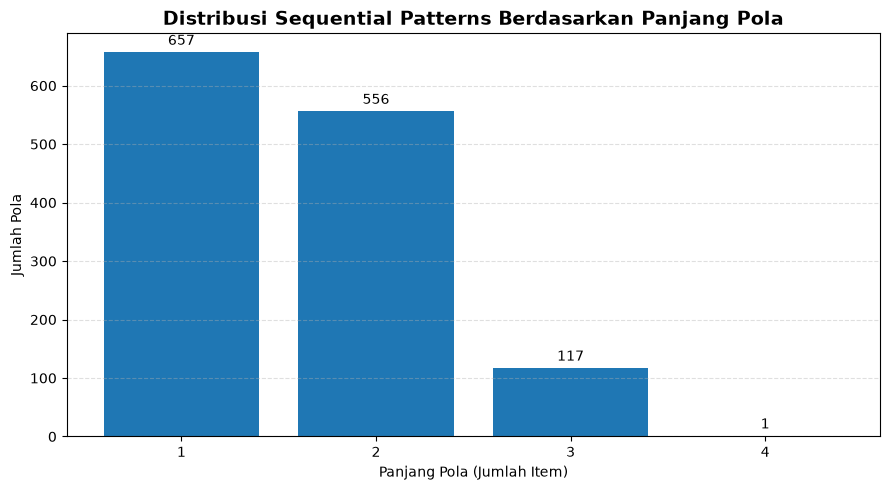

In [29]:
# Menghitung jumlah pola berdasarkan panjangnya
distribusi_pola = (pd.Series([len(p) for _, p in patterns]).value_counts().sort_index())

# Membuat visualisasi
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(distribusi_pola.index.astype(str),distribusi_pola.values)

ax.set_title('Distribusi Sequential Patterns Berdasarkan Panjang Pola',fontsize=14,fontweight='bold')
ax.set_xlabel('Panjang Pola (Jumlah Item)')
ax.set_ylabel('Jumlah Pola')

ax.grid(axis='y', linestyle='--', alpha=0.4)

ax.bar_label(bars,labels=[f'{v:,}' for v in distribusi_pola.values],padding=3)

plt.tight_layout()
plt.show()
